In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

cube_dir = Path("cubes/batch_test_64")

all_paths = sorted(cube_dir.glob("*.fits"))

if not all_paths:
    raise FileNotFoundError(f"No FITS files found in {cube_dir.resolve()}")

print(f"Found {len(all_paths)} FITS files:")
for path in all_paths:
    print(f"  {path.name}")

Found 10 FITS files:
  exponential_3d_density_N64x64x64_seed19970221.fits
  exponential_3d_velocity_N64x64x64_seed19880127.fits
  gaussian_3d_density_N64x64x64_seed19970221.fits
  gaussian_3d_velocity_N64x64x64_seed19880127.fits
  stable_3d_density_N64x64x64_seed19970221.fits
  stable_3d_velocity_N64x64x64_seed19880127.fits
  stable_alpha1_3d_density_N64x64x64_seed19970221.fits
  stable_alpha1_3d_velocity_N64x64x64_seed19880127.fits
  stable_alpha2_3d_density_N64x64x64_seed19970221.fits
  stable_alpha2_3d_velocity_N64x64x64_seed19880127.fits


In [10]:

catalog = {}

for path in all_paths:
    header = fits.getheader(path)

    key = (
        header["MODEL"].lower(),
        float(header["M3D"]),
        header["FIELD"],
    )

    if key in catalog:
        raise ValueError(
            f"Duplicate sample {key}:\n"
            f"  {catalog[key]['path']}\n"
            f"  {path}\n"
            "Select a folder containing one cube per model/alpha/field."
        )

    catalog[key] = {
        "path": path,
        "header": header,
    }

print(
    f"\n{'Model':12s} {'M3D':>5s} {'Field':8s} "
    f"{'Seed':>10s} {'Shape (x,y,z)':>18s} {'Variance':>12s}"
)

for (model, alpha, field), entry in catalog.items():
    h = entry["header"]

    shape = (h["NAXIS3"], h["NAXIS2"], h["NAXIS1"])
    variance = float(h["STD"]) ** 2

    print(
        f"{model:12s} {alpha:5.2f} {field:8s} "
        f"{h['SEED']:10d} {str(shape):>18s} "
        f"{variance:12.6f}"
    )


Model          M3D Field          Seed      Shape (x,y,z)     Variance
exponential   1.00 density    19970221       (64, 64, 64)     0.653936
exponential   1.00 velocity   19880127       (64, 64, 64)     0.636168
gaussian      2.00 density    19970221       (64, 64, 64)     0.742840
gaussian      2.00 velocity   19880127       (64, 64, 64)     0.893432
stable        1.50 density    19970221       (64, 64, 64)     0.758062
stable        1.50 velocity   19880127       (64, 64, 64)     1.009956
stable        1.00 density    19970221       (64, 64, 64)     0.951578
stable        1.00 velocity   19880127       (64, 64, 64)     0.848941
stable        2.00 density    19970221       (64, 64, 64)     0.802517
stable        2.00 velocity   19880127       (64, 64, 64)     0.829413


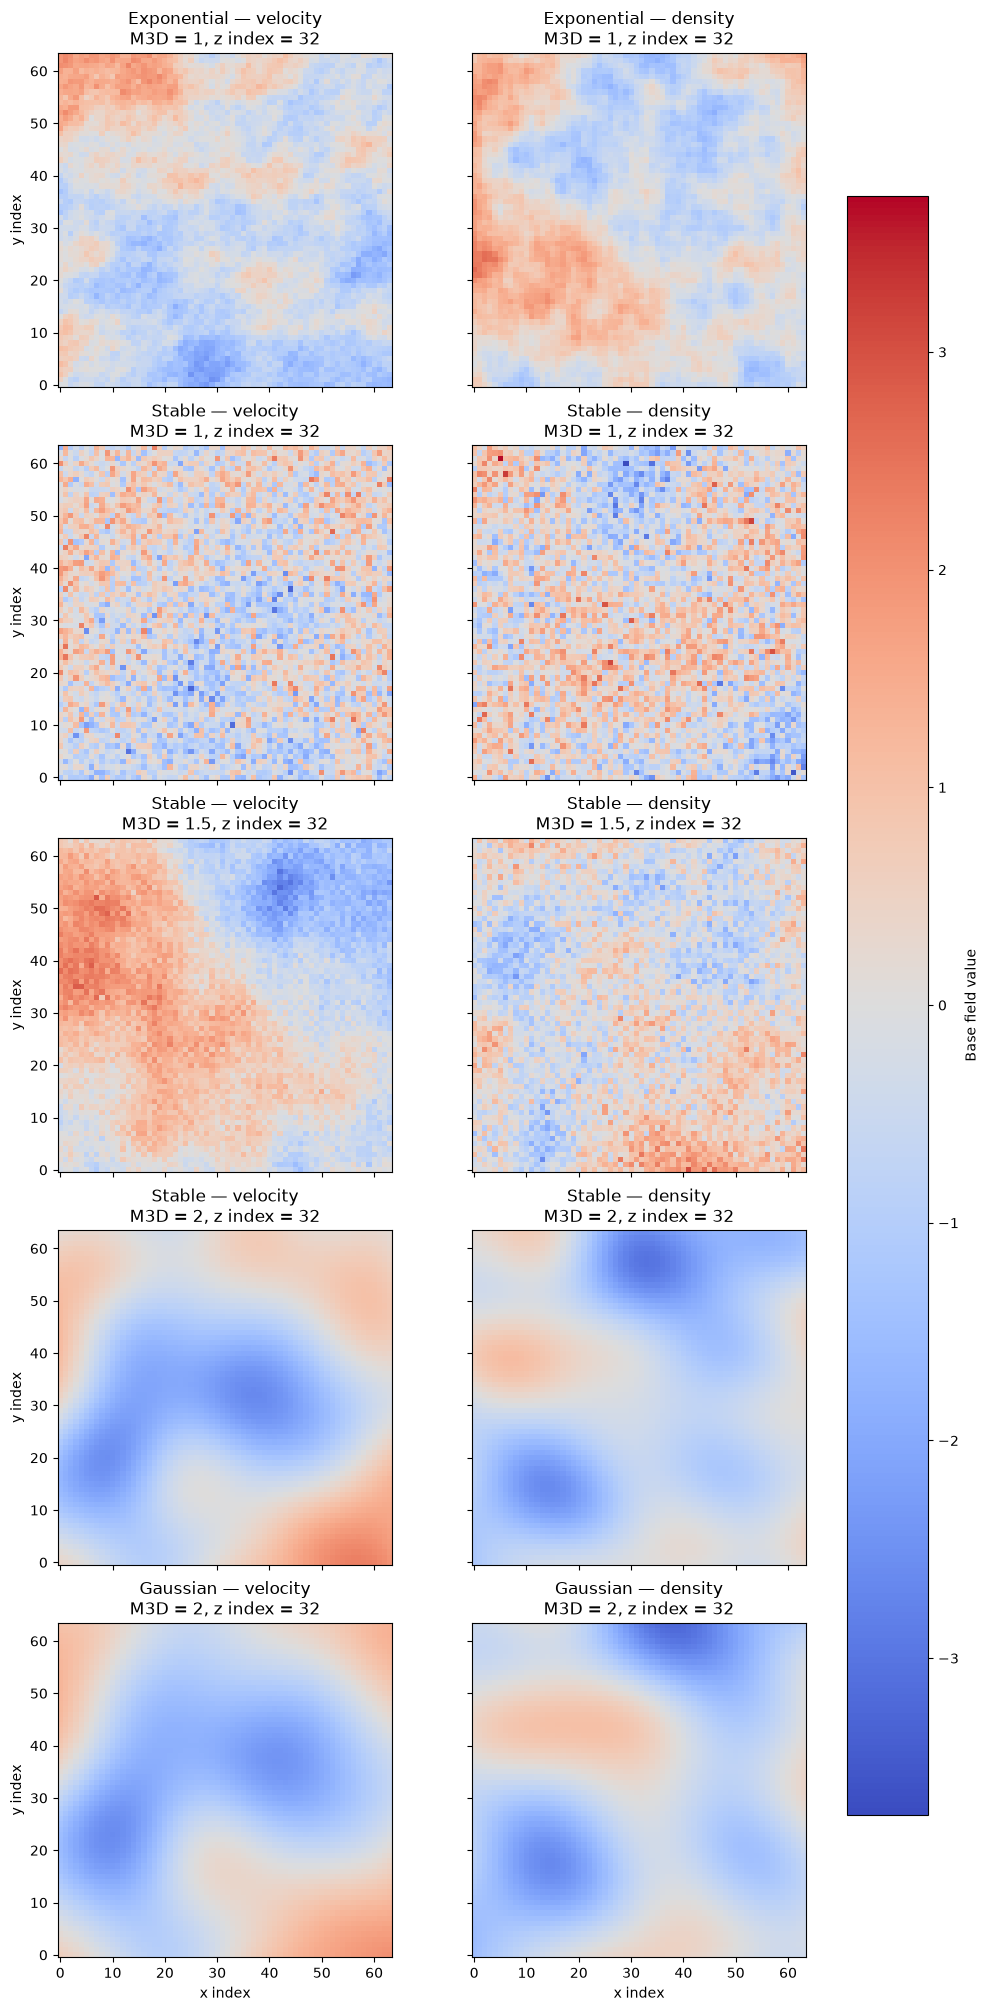

In [9]:

model_rows = [
    ("exponential", 1.0),
    ("stable", 1.0),
    ("stable", 1.5),
    ("stable", 2.0),
    ("gaussian", 2.0),
]

fields = ("velocity", "density")

# Load central z-slices, distinguishing each Stable alpha.
slices = {}

for path in all_paths:
    with fits.open(path) as hdul:
        header = hdul[0].header
        cube = hdul[0].data
        iz = cube.shape[2] // 2

        key = (
            header["MODEL"].lower(),
            float(header["M3D"]),
            header["FIELD"],
        )

        slices[key] = {
            "image": np.array(cube[:, :, iz], dtype=float),
            "iz": iz,
        }

# Shared color scale for all displayed slices.
vlim = max(
    np.abs(slices[(model, alpha, field)]["image"]).max()
    for model, alpha in model_rows
    for field in fields
)

fig, axes = plt.subplots(
    len(model_rows), 2,
    figsize=(10, 20),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for row, (model_name, alpha) in enumerate(model_rows):
    for col, field_role in enumerate(fields):
        ax = axes[row, col]
        entry = slices[(model_name, alpha, field_role)]

        im = ax.imshow(
            entry["image"].T,
            origin="lower",
            cmap="coolwarm",
            vmin=-vlim,
            vmax=vlim,
            interpolation="nearest",
        )

        ax.set_title(
            f"{model_name.capitalize()} — {field_role}\n"
            f"M3D = {alpha:g}, z index = {entry['iz']}"
        )

        if col == 0:
            ax.set_ylabel("y index")
        if row == len(model_rows) - 1:
            ax.set_xlabel("x index")

fig.colorbar(
    im,
    ax=axes,
    label="Base field value",
    shrink=0.85,
)

plt.show()

In [11]:
header = catalog[("stable", 1.5, "velocity")]["header"]

print(header)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                   64                                                  NAXIS2  =                   64                                                  NAXIS3  =                   64                                                  MODEL   = 'stable  '           / GSTools covariance model                       FIELD   = 'velocity'           / Intended role of the base scalar field         SEED    =             19880127 / Random realization seed                        M3D     =                  1.5 / Effective covariance shape exponent            ALPHA   =                  1.5 / Stable alpha or fixed model exponent           LSCALE_X=                 16.0                                                  ANGLE_X =                  0.0          